In [1]:
import sys
sys.path.append("../scripts")

from CNN import SmallCNN
import mask_classifier

import torch.nn as nn
import torch
import torch.optim as optim

import matplotlib.pyplot as plt

In [2]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(device)

cuda:0


In [7]:
model = SmallCNN().to(device) 

optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
criterion = nn.BCEWithLogitsLoss()

train_loader, test_loader = mask_classifier.create_dataset(batch_size=32)
num_epochs = 30

In [8]:
history = mask_classifier.train(train_loader, test_loader, optimizer, criterion, model, epochs=num_epochs, device=device)

Training: 100%|██████████| 30/30 [03:50<00:00,  7.68s/epoch, best=0.1175, train_loss=0.0676, val_acc=93.5%, val_loss=0.1633]


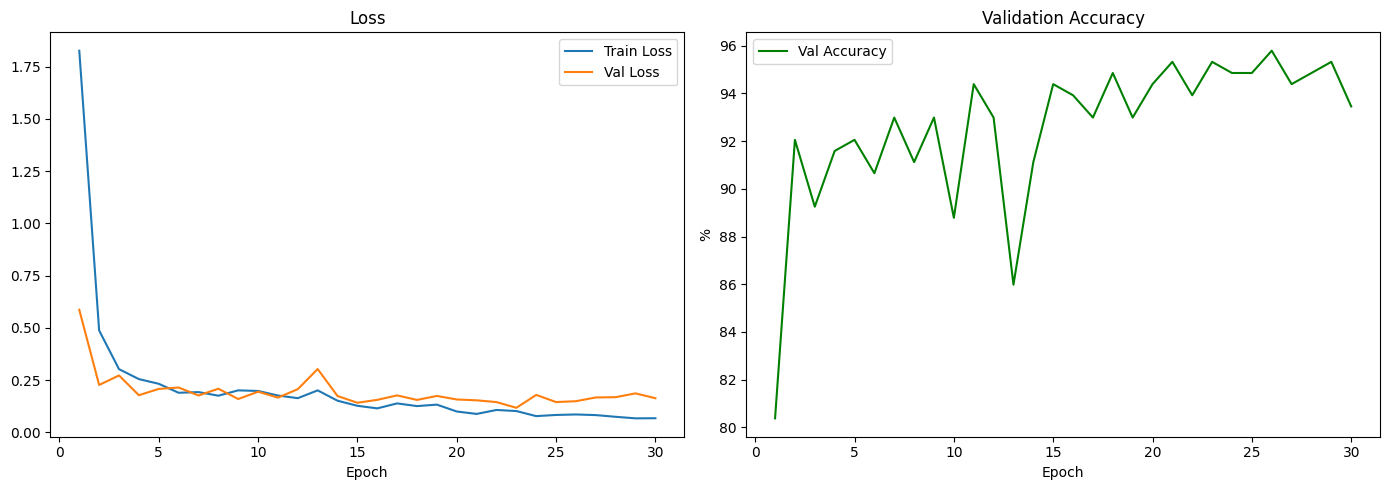

In [9]:
epochs_range = range(1, num_epochs + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss plot
ax1.plot(epochs_range, history["train_loss"], label="Train Loss")
ax1.plot(epochs_range, history["val_loss"], label="Val Loss")
ax1.set_title("Loss")
ax1.set_xlabel("Epoch")
ax1.legend()

# Accuracy plot
ax2.plot(epochs_range, history["val_acc"], label="Val Accuracy", color="green")
ax2.set_title("Validation Accuracy")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("%")
ax2.legend()

plt.tight_layout()
plt.show()

In [15]:
print(history["train_loss"])
print(history["val_loss"])
print(history["val_acc"])

[1.8259023152015827, 0.4876062269150107, 0.30237104302203216, 0.25483102613577135, 0.23244536612872724, 0.18944819823459344, 0.19267506511123092, 0.17548290529736765, 0.20096958649379235, 0.1980462455087238, 0.1762961941184821, 0.1636483903836321, 0.20090531281850957, 0.15144773724454422, 0.1271076583200031, 0.11481454299279938, 0.13859775676219552, 0.12569138559478302, 0.13276789709925652, 0.09981882020279213, 0.08823655111094315, 0.10717414767929802, 0.10194791025585598, 0.0777402430496834, 0.08334227651357651, 0.0856274140101892, 0.08260406574441327, 0.07446110238217646, 0.06711913321029257, 0.06763840859962834]
[0.5863602416855949, 0.22670776503426687, 0.2723732058491026, 0.1778171786240169, 0.20795951783657074, 0.2145748883485794, 0.17643883398600987, 0.20885789820126124, 0.1595501218523298, 0.19465865407671248, 0.1662640172455992, 0.20670577032225473, 0.3030552225453513, 0.17380692596946443, 0.1417312898806163, 0.15556533528225763, 0.17691787970917566, 0.15518820924418314, 0.1742

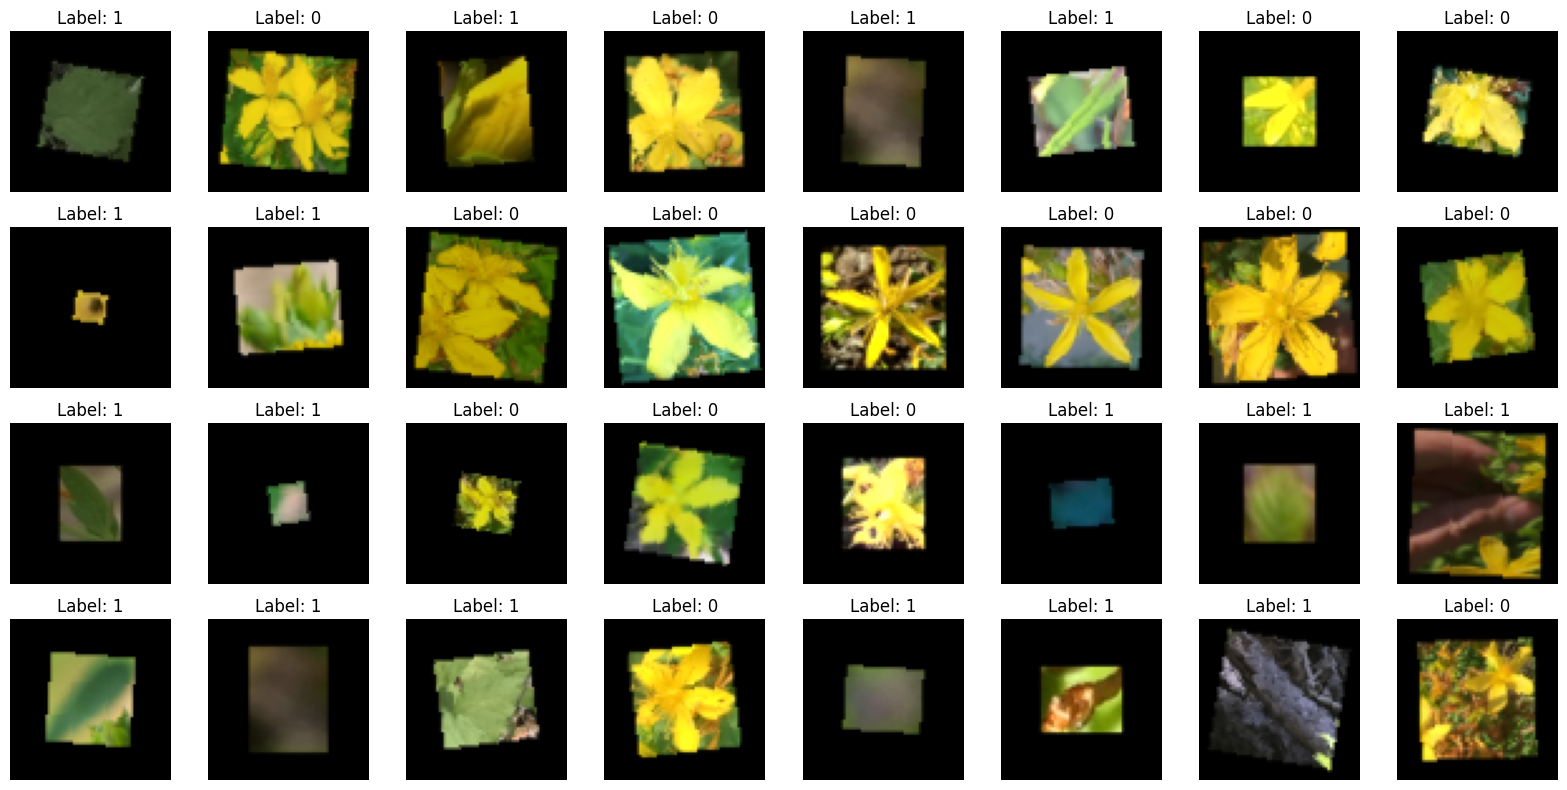

In [ ]:
# Visualize random samples from each class to spot bad labels
import random

fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for idx, ax in enumerate(axes.flatten()):
    img, label = train_loader.dataset[random.randint(0, len(train_loader.dataset)-1)]
    img = img.permute(1, 2, 0) * 0.5 + 0.5  # denormalize
    ax.imshow(img)

    if label == 1:
        label_name = "Flower"
    else:
        label_name = "No Flower"
    ax.set_title(f"Label: {label_name}")
    ax.axis("off")
plt.tight_layout()
plt.show()

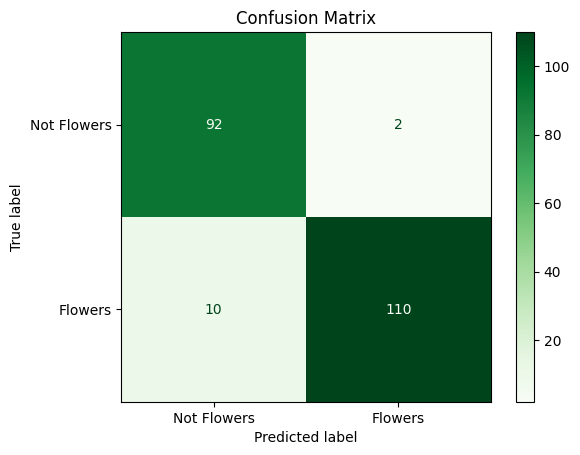

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay

all_preds, all_labels = [], []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1)
        outputs = model(images)
        predicted = (outputs >= 0.0).float()
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

ConfusionMatrixDisplay.from_predictions(
    all_labels,
    all_preds,
    display_labels=["Not Flowers", "Flowers"],
    cmap="Greens"
)
plt.title("Confusion Matrix")
plt.show()